# Experiment No 7
## Implementation of a Simple Autoencoder for Dimensionality Reduction and Feature Learning

**Name:** Mohamed Aashik S  
**Roll No.:** 24BAD072

## Part A: Dataset Preparation

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)


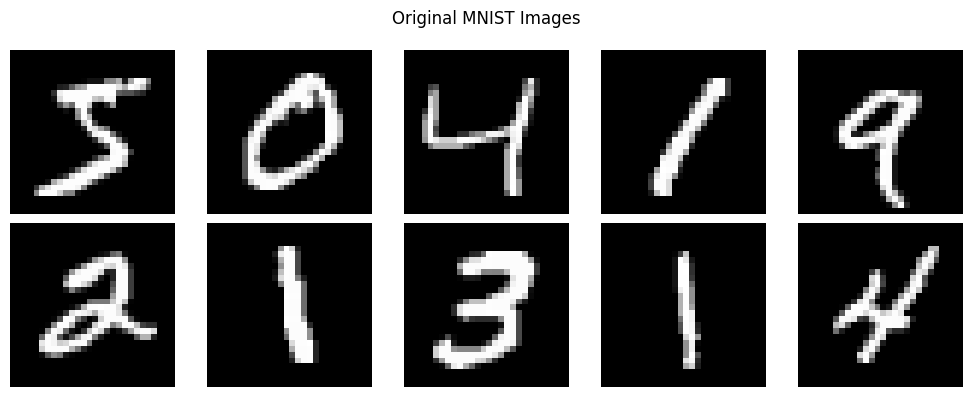

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 28 * 28)
x_test = x_test.reshape(-1, 28 * 28)

print("Flattened training shape:", x_train.shape)
print("Flattened testing shape:", x_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()


## Part B: Implementing the Autoencoder Model

In [2]:
input_dim = 784
encoding_dim = 32

input_layer = tf.keras.Input(shape=(input_dim,), name="input")

encoded = tf.keras.layers.Dense(128, activation="relu", name="encoder_hidden")(input_layer)
bottleneck = tf.keras.layers.Dense(encoding_dim, activation="relu", name="bottleneck")(encoded)

decoded = tf.keras.layers.Dense(128, activation="relu", name="decoder_hidden")(bottleneck)
output_layer = tf.keras.layers.Dense(input_dim, activation="sigmoid", name="output")(decoded)

autoencoder = tf.keras.Model(input_layer, output_layer, name="MNIST_Autoencoder")
encoder = tf.keras.Model(input_layer, bottleneck, name="Encoder")

latent_input = tf.keras.Input(shape=(encoding_dim,))
decoder_hidden = autoencoder.get_layer("decoder_hidden")(latent_input)
decoder_output = autoencoder.get_layer("output")(decoder_hidden)
decoder = tf.keras.Model(latent_input, decoder_output, name="Decoder")

autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.summary()


Model: "MNIST_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Model Training and Performance Evaluation

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0586 - val_loss: 0.0321
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0262 - val_loss: 0.0213
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0198 - val_loss: 0.0177
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0169 - val_loss: 0.0157
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0153 - val_loss: 0.0143
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0141 - val_loss: 0.0133
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0133 - val_loss: 0.0126
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0127 - val_loss: 0.0122
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0124 - val_loss: 0.0119
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0121 - val_loss: 0.0116
Test Reconstruction MSE: 0.011580285616219044


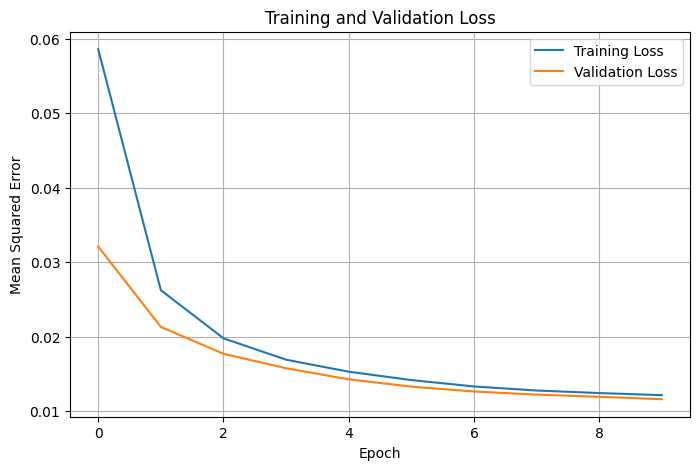

In [3]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
print("Test Reconstruction MSE:", test_loss)

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


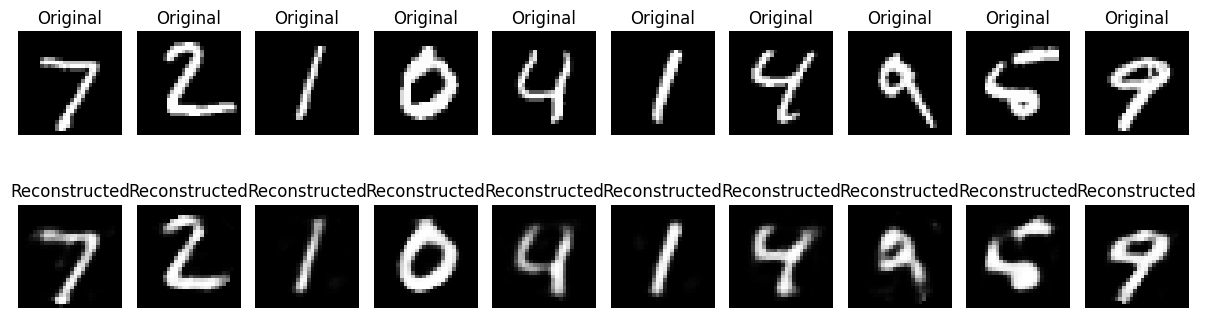

In [10]:
reconstructed_images = autoencoder.predict(x_test[:10])
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Part D: Dimensionality Reduction and Feature Visualization

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original data dimensions: (10000, 784)
Compressed representation dimensions: (10000, 32)


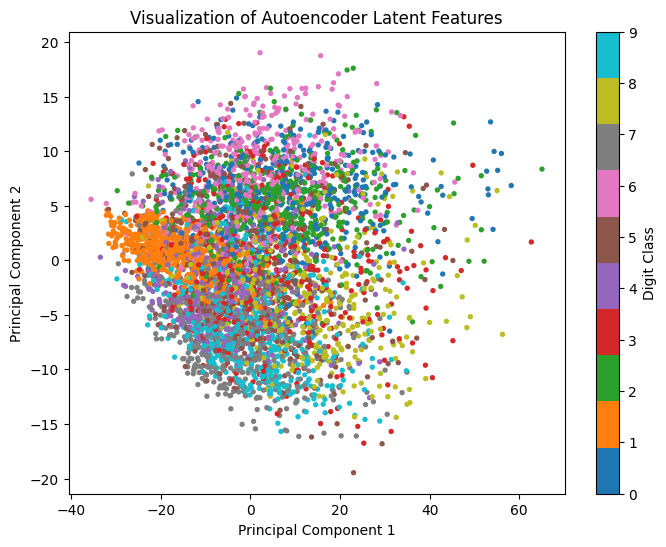

In [11]:
latent_features = encoder.predict(x_test)

print("Original data dimensions:", x_test.shape)
print("Compressed representation dimensions:", latent_features.shape)

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features[:5000])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:5000],
    cmap="tab10",
    s=8
)
plt.colorbar(scatter, label="Digit Class")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Visualization of Autoencoder Latent Features")
plt.show()


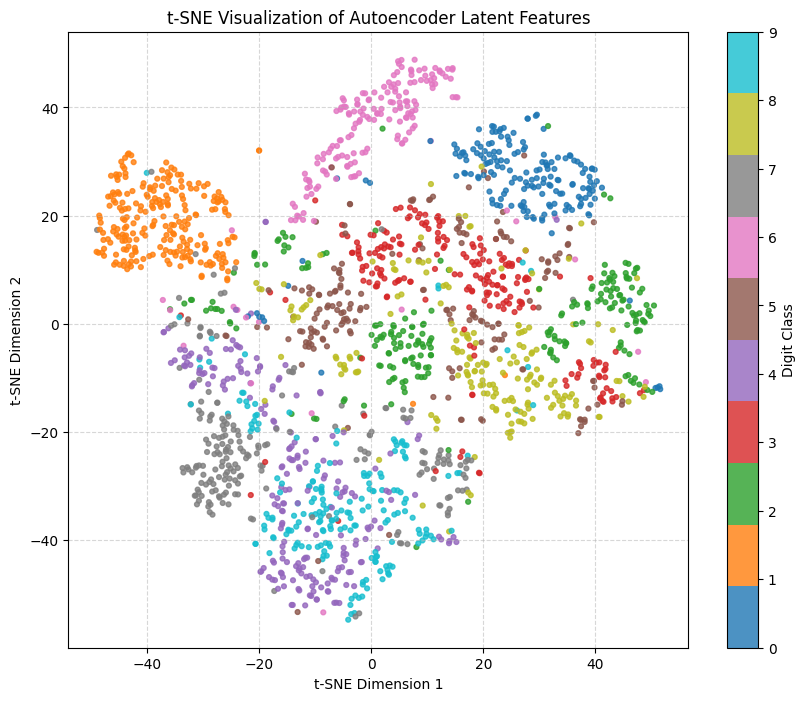

In [9]:
from sklearn.manifold import TSNE

num_samples = 2000

tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, n_jobs=-1)
latent_tsne = tsne.fit_transform(latent_features[:num_samples])

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    latent_tsne[:, 0],
    latent_tsne[:, 1],
    c=y_test[:num_samples],
    cmap="tab10",
    s=12,
    alpha=0.8
)
plt.colorbar(scatter, label="Digit Class")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE Visualization of Autoencoder Latent Features")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


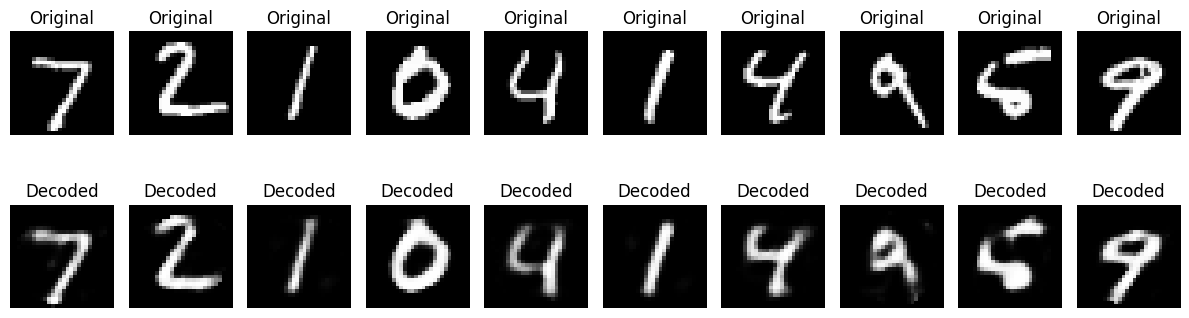

Observation: The Encoder reduces each 784-dimensional image to 32 features.
The Decoder reconstructs the image from the compressed latent representation.


In [6]:
selected_latent = latent_features[:10]
decoder_reconstruction = decoder.predict(selected_latent)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.title("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(decoder_reconstruction[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.title("Decoded")

plt.tight_layout()
plt.show()

print("Observation: The Encoder reduces each 784-dimensional image to 32 features.")
print("The Decoder reconstructs the image from the compressed latent representation.")
